### Importando bibliotecas ###

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt 

### Carregando e visualizando os dados ###

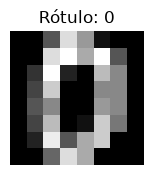

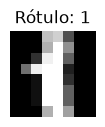

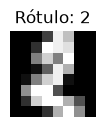

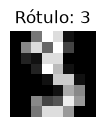

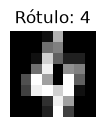

In [6]:
# Base de dados (imagens de dígitos de 0 a 9)
digits = load_digits()
# Visualizar 5 exemplos
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title(f'Rótulo: {digits.target[i]}')
    plt.axis('off')
    plt.show() 

### Dividindo os dados (aprendizado supervisionado) ###

In [7]:
# Dados e rótulos
X = digits.data # vetores de pixels
y = digits.target # dígitos reais 

In [8]:
# Padronização dos dados
scaler = StandardScaler() 
X_scaled = scaler.fit_transform(X) 

In [9]:
# Separar treino e teste (80% treino com rótulos, 20%teste)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42) 

### Criando e treinando uma MLP com backpropagation ###

In [11]:
# MLP com 1 camada oculta de 50 neurônios
mlp = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', solver='adam', max_iter=500, random_state=1) 

In [12]:
# Treinamento supervisionado com backpropagation
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(50,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",1
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


### Avaliando a performance ###

In [14]:
y_pred = mlp.predict(X_test)
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      0.97      0.98        33
           3       0.94      0.97      0.96        34
           4       1.00      1.00      1.00        46
           5       0.96      0.94      0.95        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       1.00      1.00      1.00        30
           9       0.93      0.97      0.95        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



### Visualizando a matriz de confusão: ###

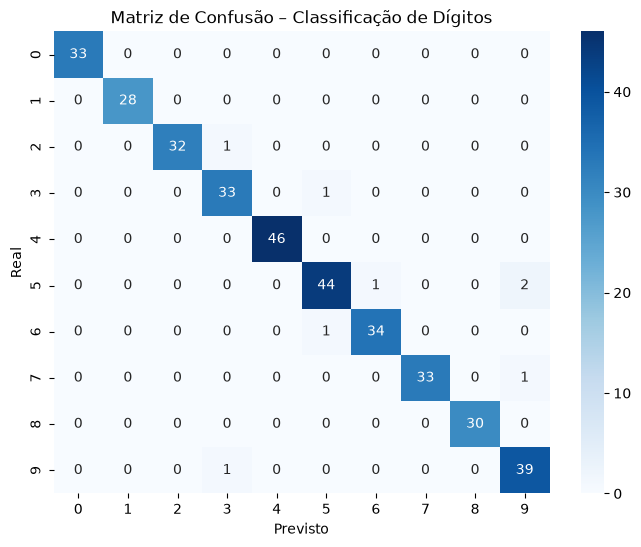

In [16]:
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão – Classificação de Dígitos")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show() 

In [18]:
# Extensão: Aprendizado Não Supervisionado(Clustering)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans 

In [19]:
# Redução de dimensionalidade para visualização 
pca = PCA(n_components=2) 
X_pca = pca.fit_transform(X_scaled) 

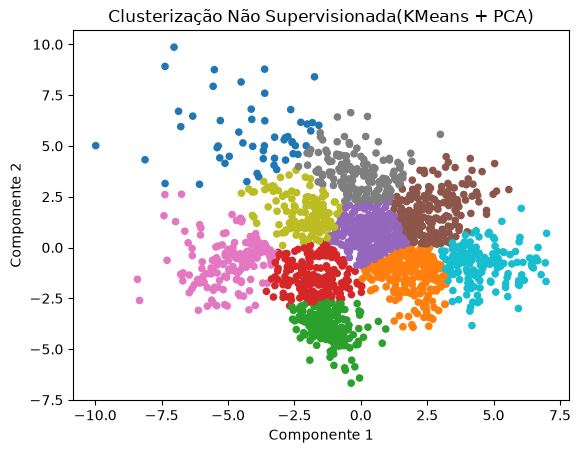

In [21]:
# KMeans para clusterização não supervisionada
kmeans = KMeans(n_clusters=10, random_state=42)
clusters = kmeans.fit_predict(X_pca)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='tab10', s=20)
plt.title("Clusterização Não Supervisionada(KMeans + PCA)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.show() 

In [22]:
# Extensão: Aprendizado Semissupervisionado(simulado)
# Aqui usamos apenas 10% dos rótulos e tentamos treinar a MLP:
from sklearn.semi_supervised import SelfTrainingClassifier 

In [23]:
# Selecionando aleatoriamente 10% dos rótulos para treino supervisionado
import numpy as np

rng = np.random.RandomState(42)
n_labeled = int(len(X_train) * 0.1)
labels = -1 * np.ones_like(y_train)
indices_rotulados = rng.choice(len(y_train), size=n_labeled, replace=False)
labels[indices_rotulados] = y_train[indices_rotulados] 

In [26]:
# MLP como base para aprendizado semissupervisionado
base_mlp = MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=1)
self_training_model = SelfTrainingClassifier(base_mlp)
self_training_model.fit(X_train, labels)

,"estimator estimator: estimator objectAn estimator object implementing `fit` and `predict_proba`.Invoking the `fit` method will fit a clone of the passed estimator,which will be stored in the `estimator_` attribute... versionadded:: 1.6 `estimator` was added to replace `base_estimator`.",MLPClassifier...andom_state=1)
,"threshold threshold: float, default=0.75The decision threshold for use with `criterion='threshold'`.Should be in [0, 1). When using the `'threshold'` criterion, a:ref:`well calibrated classifier <calibration>` should be used.",0.75
,"criterion criterion: {'threshold', 'k_best'}, default='threshold'The selection criterion used to select which labels to add to thetraining set. If `'threshold'`, pseudo-labels with predictionprobabilities above `threshold` are added to the dataset. If `'k_best'`,the `k_best` pseudo-labels with highest prediction probabilities areadded to the dataset. When using the 'threshold' criterion, a:ref:`well calibrated classifier <calibration>` should be used.",'threshold'
,"k_best k_best: int, default=10The amount of samples to add in each iteration. Only used when`criterion='k_best'`.",10
,"max_iter max_iter: int or None, default=10Maximum number of iterations allowed. Should be greater than or equalto 0. If it is `None`, the classifier will continue to predict labelsuntil no new pseudo-labels are added, or all unlabeled samples havebeen labeled.",10
,"verbose verbose: bool, default=FalseEnable verbose output.",False
Name,Type,Value
"classes_ classes_: ndarray or list of ndarray of shape (n_classes,)Class labels for each output. (Taken from the trained`estimator_`).","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
estimator_ estimator_: estimator objectThe fitted estimator.,MLPClassifier,MLPClassifier...andom_state=1)
"labeled_iter_ labeled_iter_: ndarray of shape (n_samples,)The iteration in which each sample was labeled. When a sample hasiteration 0, the sample was already labeled in the original dataset.When a sample has iteration -1, the sample was not labeled in anyiteration.","ndarray[int64](1437,)","[1,1,1,...,1,2,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,64


In [27]:
# Avaliação
print("Avaliação do Modelo Semissupervisionado:")
print(classification_report(y_test, self_training_model.predict(X_test))) 

Avaliação do Modelo Semissupervisionado:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        33
           1       0.88      1.00      0.93        28
           2       0.97      0.97      0.97        33
           3       1.00      0.91      0.95        34
           4       1.00      1.00      1.00        46
           5       0.94      0.94      0.94        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.87      0.87      0.87        30
           9       0.92      0.90      0.91        40

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360

